# Ekstraksi Fitur Citra Sepatu & Klasifikasi

**Kelompok / anggota:** (isi nama anggota)  
**Tujuan:** membedakan sepatu `berantakan` dan `tidak_berantakan` dari statistik warna RGB dan tekstur GLCM.

Dataset lokal menggunakan folder `berantakan/` dan `rapi/`. Notebook memetakan nama folder `rapi` menjadi label `tidak_berantakan` agar sesuai PRD. Alur mencakup EDA, ekstraksi 14 fitur, perbandingan lima model, dan evaluasi holdout.

**Acuan rumus:** Hallur & Gavade (2025), *Image feature extraction techniques: A comprehensive review*, Franklin Open 12, 100366.

## 0. Instalasi pustaka

Jalankan notebook dari atas. Sel berikut memasang otomatis pustaka wajib yang belum tersedia pada kernel Jupyter aktif. `scikit-image` opsional untuk sanity check `graycoprops` dan eksperimen HOG/LBP.

In [21]:
import importlib.util

required_packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "PIL": "Pillow", "sklearn": "scikit-learn", "tqdm": "tqdm",
}
missing_packages = [pip_name for module_name, pip_name in required_packages.items()
                    if importlib.util.find_spec(module_name) is None]
if missing_packages:
    print("Memasang pustaka yang belum tersedia:", ", ".join(missing_packages))
    get_ipython().run_line_magic("pip", "install -q " + " ".join(missing_packages))
else:
    print("Semua pustaka wajib sudah terpasang.")
if importlib.util.find_spec("skimage") is None:
    print("scikit-image opsional belum ada. Untuk graycoprops dan HOG/LBP: %pip install scikit-image")

Semua pustaka wajib sudah terpasang.


### Verifikasi versi pustaka

Memastikan kernel yang aktif benar-benar memuat pustaka yang dibutuhkan beserta versinya.


In [22]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from PIL import Image

try:
    import skimage
    skimage_version = skimage.__version__
except ImportError:
    skimage_version = "tidak terpasang (fallback NumPy dipakai)"

print("Python       :", sys.version.split()[0])
print("numpy        :", np.__version__)
print("pandas       :", pd.__version__)
print("matplotlib   :", matplotlib.__version__)
print("seaborn      :", sns.__version__)
print("Pillow       :", Image.__version__)
print("scikit-learn :", sklearn.__version__)
print("scikit-image :", skimage_version)


Python       : 3.9.10
numpy        : 2.0.2
pandas       : 2.3.3
matplotlib   : 3.9.4
seaborn      : 0.13.2
Pillow       : 11.3.0
scikit-learn : 1.6.1
scikit-image : 0.24.0


## 1. Import, lingkungan, dan konfigurasi

Bagian ini memuat pustaka serta satu tempat untuk mengatur path, ukuran citra, parameter GLCM, dan random state. Path default menunjuk folder proyek yang berisi `rapi/` dan `berantakan/`.

In [23]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

try:
    from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern
    SKIMAGE_AVAILABLE = True
except ImportError:
    SKIMAGE_AVAILABLE = False

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
DATASET_DIR = Path("dataset")
OUTPUT_DIR = None
IMG_SIZE = (256, 256)  # kanvas, rasio aspek citra dipertahankan
CSV_WARNA = "fitur_warna.csv"
CSV_FINAL = "fitur_lengkap.csv"
FOLDER_TO_LABEL = {"berantakan": "berantakan", "rapi": "tidak_berantakan"}
CLASS_LABELS = ["berantakan", "tidak_berantakan"]
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png"}
GLCM_LEVELS = 256
GLCM_DISTANCES = [1]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
N_SPLITS = 5

if not 2 <= GLCM_LEVELS <= 256:
    raise ValueError("GLCM_LEVELS harus berada di antara 2 dan 256.")
if IMG_SIZE is not None and (len(IMG_SIZE) != 2 or min(IMG_SIZE) <= 0):
    raise ValueError("IMG_SIZE harus None atau pasangan ukuran positif.")
if not (DATASET_DIR / "berantakan").is_dir() and (Path("..") / DATASET_DIR).is_dir():
    DATASET_DIR = Path("..") / DATASET_DIR
DATASET_DIR = DATASET_DIR.resolve()
PROJECT_ROOT = DATASET_DIR.parent if DATASET_DIR.name == "dataset" else DATASET_DIR
OUTPUT_DIR = PROJECT_ROOT
RESAMPLE_LANCZOS = Image.Resampling.LANCZOS if hasattr(Image, "Resampling") else Image.LANCZOS
print(f"Folder dataset: {DATASET_DIR}")
print(f"Folder output CSV: {OUTPUT_DIR}")
print(f"scikit-image tersedia: {SKIMAGE_AVAILABLE}")

Folder dataset: C:\laragon\www\messy-shoe-cv\dataset
Folder output CSV: C:\laragon\www\messy-shoe-cv
scikit-image tersedia: True


## 2. Inventaris dan validasi dataset

Notebook membaca gambar dari dua folder kelas yang diharapkan, lalu memetakan nama folder ke label tugas. Kelas yang hilang atau dataset tanpa gambar menghasilkan pesan yang jelas.

In [24]:
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Folder dataset tidak ditemukan: {DATASET_DIR}. Atur DATASET_DIR pada sel konfigurasi.")

missing_folders = [name for name in FOLDER_TO_LABEL if not (DATASET_DIR / name).is_dir()]
if missing_folders:
    expected = ", ".join(str(DATASET_DIR / name) for name in missing_folders)
    raise FileNotFoundError(f"Folder kelas tidak ditemukan: {expected}. Pastikan kedua folder dataset tersedia.")

file_records = []
for folder_name, label in FOLDER_TO_LABEL.items():
    folder = DATASET_DIR / folder_name
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS:
            filename = path.relative_to(DATASET_DIR).as_posix()
            match = re.match(r"^(\d{2}-\d{3})", path.stem)
            group_id = match.group(1) if match else f"file:{filename}"
            file_records.append({
                "path": path, "filename": filename, "folder": folder_name,
                "label": label, "group_id": group_id,
            })

if not file_records:
    raise ValueError(
        f"Tidak ada gambar .jpg, .jpeg, atau .png di {DATASET_DIR}. "
        "Periksa path dan isi folder kelas."
    )

df_files = pd.DataFrame(file_records)
print(f"Gambar terdaftar: {len(df_files)}")
display(df_files.groupby("label").size().reindex(CLASS_LABELS, fill_value=0).rename("jumlah file").to_frame())

Gambar terdaftar: 194


,jumlah file
label,
berantakan,97
tidak_berantakan,97


## 3. EDA awal: kualitas, ukuran, dan contoh gambar

Tahap ini memeriksa apakah gambar benar-benar bisa dibuka, membandingkan jumlah tiap kelas dan variasi ukuran asli, lalu menampilkan contoh RGB. Gambar rusak dilewati dan dicatat di `df_gambar_gagal`. Tiap pemeriksaan diletakkan pada sel terpisah dengan keluarannya masing-masing.


### 3.1 Memuat dan memvalidasi gambar

Semua gambar dibuka, dikonversi ke RGB, lalu di-resize ke `IMG_SIZE`. Gambar yang gagal dibaca dikumpulkan tanpa menghentikan proses.


In [25]:
image_cache = {}
valid_records = []
failed_records = []
for record in tqdm(file_records, desc="Memeriksa dan menyiapkan gambar", mininterval=1.0):
    try:
        with Image.open(record["path"]) as source:
            source.load()
            original_width, original_height = source.size
            rgb_image = source.convert("RGB")
            if IMG_SIZE is not None:
                rgb_image = ImageOps.contain(rgb_image, IMG_SIZE, method=RESAMPLE_LANCZOS)
                resized = np.asarray(rgb_image, dtype=np.uint8)
                target_width, target_height = IMG_SIZE
                pad_height, pad_width = target_height - resized.shape[0], target_width - resized.shape[1]
                top, left = pad_height // 2, pad_width // 2
                bottom, right = pad_height - top, pad_width - left
                rgb = np.pad(resized, ((top, bottom), (left, right), (0, 0)), mode="reflect")
            else:
                rgb = np.asarray(rgb_image, dtype=np.uint8)
        path_key = str(record["path"])
        image_cache[path_key] = rgb
        valid_records.append({**record, "width": original_width, "height": original_height,
                              "rasio_aspek": original_width / original_height})
    except Exception as error:
        failed_records.append({"filename": record["filename"], "error": str(error)})

df_gambar_gagal = pd.DataFrame(failed_records, columns=["filename", "error"])
df_images = pd.DataFrame(valid_records)
if df_images.empty:
    raise ValueError("Tidak ada gambar yang dapat dibaca. Periksa file dan format gambar.")
counts = df_images["label"].value_counts().reindex(CLASS_LABELS, fill_value=0)
if (counts == 0).any():
    raise ValueError(f"Ada kelas kosong setelah gambar rusak dilewati: {counts[counts == 0].index.tolist()}.")
if counts.min() < N_SPLITS:
    raise ValueError(f"Setiap kelas memerlukan sedikitnya {N_SPLITS} gambar untuk CV.")
print(f"Gambar valid: {len(df_images)} | Gambar dilewati: {len(df_gambar_gagal)}")
print(f"ID/grup untuk split: {df_images['group_id'].nunique()}")
if not df_gambar_gagal.empty:
    display(df_gambar_gagal)
else:
    print("Tidak ditemukan gambar rusak atau tidak terbaca.")

Memeriksa dan menyiapkan gambar: 100%|██████████| 194/194 [00:26<00:00,  7.21it/s]

Gambar valid: 194 | Gambar dilewati: 0
ID/grup untuk split: 58
Tidak ditemukan gambar rusak atau tidak terbaca.


### 3.2 Komposisi kelas dan rasio aspek

Membandingkan jumlah gambar valid per kelas dan sebaran rasio aspek asli, untuk memastikan kedua kelas seimbang dan tidak ada kelompok gambar dengan bentuk yang menyimpang.


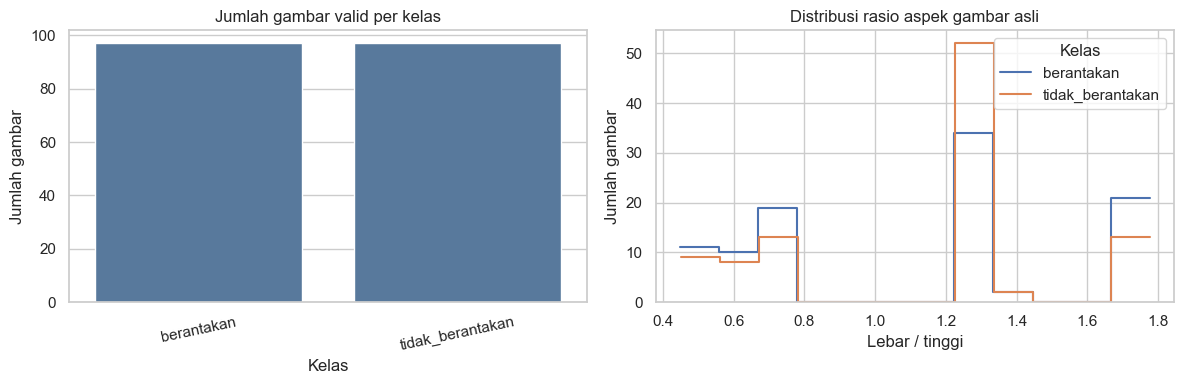

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_images, x="label", order=CLASS_LABELS, color="#4c78a8", ax=axes[0])
axes[0].set_title("Jumlah gambar valid per kelas")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah gambar")
axes[0].tick_params(axis="x", rotation=12)

for label in CLASS_LABELS:
    subset = df_images.loc[df_images["label"] == label, "rasio_aspek"]
    sns.histplot(subset, bins=12, element="step", fill=False, label=label, ax=axes[1])
axes[1].set_title("Distribusi rasio aspek gambar asli")
axes[1].set_xlabel("Lebar / tinggi")
axes[1].set_ylabel("Jumlah gambar")
axes[1].legend(title="Kelas")

plt.tight_layout()
plt.show()


### 3.3 Ringkasan ukuran gambar asli

Statistik lebar, tinggi, dan rasio aspek sebelum resize, untuk mendokumentasikan variasi resolusi dataset.


In [27]:
display(df_images.groupby("label")[["width", "height", "rasio_aspek"]].describe().round(2))


width                                                   \
                 count     mean      std    min     25%     50%     75%   
label                                                                     
berantakan        97.0  2527.82  1375.37  590.0  1200.0  2340.0  4000.0   
tidak_berantakan  97.0  2781.67  1388.88  590.0  1599.0  3060.0  4064.0   

                         height                                           \
                     max  count     mean      std    min     25%     50%   
label                                                                      
berantakan        4608.0   97.0  2252.39  1034.72  899.0  1280.0  2160.0   
tidak_berantakan  4608.0   97.0  2395.76  1019.50  372.0  1390.0  3000.0   

                                 rasio_aspek                                \
                     75%     max       count  mean   std   min   25%   50%   
label                                                                        
berantakan        3048.0  4608.0        97.0  1.14  0.47  0.45  0.75  1.33   
tidak_berantakan  3072.0  4608.0        97.0  1.17  0.41  0.45  0.75  1.33   

                              
                   75%   max  
label                         
berantakan        1.33  1.78  
tidak_berantakan  1.33  1.78

### 3.4 Contoh gambar setelah resize

Tiga contoh dari setiap kelas setelah ukuran diseragamkan, sebagai pemeriksaan visual bahwa resize dan konversi RGB berjalan benar.


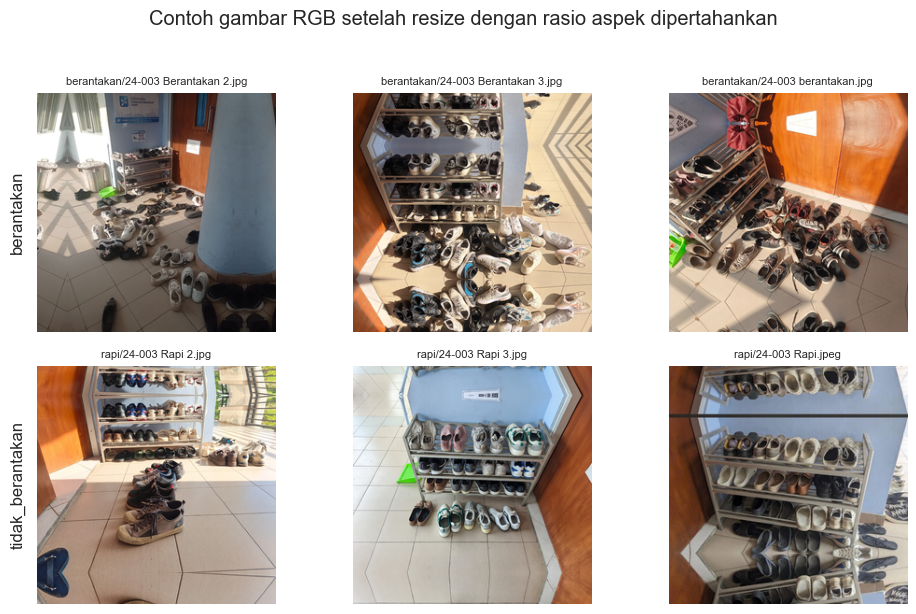

In [28]:
fig, axes = plt.subplots(len(CLASS_LABELS), 3, figsize=(10, 6))
for row_index, label in enumerate(CLASS_LABELS):
    samples = df_images[df_images["label"] == label].head(3)
    for col_index, ax in enumerate(axes[row_index]):
        if col_index < len(samples):
            record = samples.iloc[col_index]
            ax.imshow(image_cache[str(record["path"])])
            ax.set_title(record["filename"], fontsize=8)
        else:
            ax.set_visible(False)
        ax.axis("off")
    axes[row_index, 0].text(-0.05, 0.5, label, transform=axes[row_index, 0].transAxes,
                            rotation=90, va="center", ha="right")
fig.suptitle("Contoh gambar RGB setelah resize dengan rasio aspek dipertahankan", y=1.02)
plt.tight_layout()
plt.show()


## 4. Ekstraksi fitur warna RGB

Fitur dihitung terpisah untuk channel merah, hijau, dan biru. Std memakai pembagi populasi $N$ (Eq. 3), sedangkan skewness memakai momen ketiga tanpa koreksi sampel (Eq. 4); jika satu channel konstan, skewness ditetapkan 0.

| Fitur | Rumus jurnal |
|---|---|
| Mean (Eq. 2) | $\mu_c = \frac{1}{M \times N}\sum_i\sum_j C(i,j)$ |
| Std (Eq. 3) | $\sigma = \sqrt{\frac{1}{N}\sum_i(x_i-\mu)^2}$ |
| Skewness (Eq. 4) | $\frac{1}{M \times N}\sum_i\sum_j\left(\frac{I(i,j)-\mu}{\sigma}\right)^3$ |

In [29]:
def channel_stats(channel):
    mean = channel.mean()                                  # Eq. (2)
    std = np.sqrt(np.mean((channel - mean) ** 2))          # Eq. (3), pembagi N
    skew = 0.0 if std == 0 else np.mean(((channel - mean) / std) ** 3)  # Eq. (4)
    return float(mean), float(std), float(skew)

color_columns = [f"{stat}_{channel}" for stat in ("mean", "std", "skew") for channel in "RGB"]
color_rows = []

for record in tqdm(valid_records, desc="Ekstraksi fitur warna", mininterval=1.0):
    rgb = image_cache[str(record["path"])].astype(np.float64)
    stats = [channel_stats(rgb[:, :, index]) for index in range(3)]
    row = {"filename": record["filename"]}
    for index, channel in enumerate("RGB"):
        row[f"mean_{channel}"] = stats[index][0]
        row[f"std_{channel}"] = stats[index][1]
        row[f"skew_{channel}"] = stats[index][2]
    row["label"] = record["label"]
    color_rows.append(row)

df_warna = pd.DataFrame(color_rows)[["filename"] + color_columns + ["label"]]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
path_csv_warna = OUTPUT_DIR / CSV_WARNA
df_warna.to_csv(path_csv_warna, index=False)
print(f"CSV fitur warna: {path_csv_warna} | bentuk: {df_warna.shape}")
display(df_warna.head())

Ekstraksi fitur warna: 100%|██████████| 194/194 [00:01<00:00, 151.61it/s]

CSV fitur warna: C:\laragon\www\messy-shoe-cv\fitur_warna.csv | bentuk: (194, 11)


,filename,mean_R,mean_G,mean_B,std_R,std_G,std_B,skew_R,skew_G,skew_B,label
0,berantakan/24-003 Berantakan 2.jpg,110.720367,105.561218,101.683975,56.894741,55.378934,54.183069,0.748670,0.701999,0.644443,berantakan
1,berantakan/24-003 Berantakan 3.jpg,149.705353,130.862045,113.433289,73.453635,70.071445,63.511628,-0.222975,-0.139022,-0.126647,berantakan
2,berantakan/24-003 berantakan.jpg,150.763809,115.106903,90.900269,69.306975,57.372256,54.139031,-0.136816,0.171352,0.531602,berantakan
3,berantakan/24-006 Berantakan 1.jpg,120.780609,112.721039,109.308685,52.646323,50.919134,50.715847,-0.503351,-0.256659,-0.177175,berantakan
4,berantakan/24-006 Berantakan 2.jpg,127.230789,120.406448,117.175781,53.968538,50.034993,48.653675,-0.789952,-0.584725,-0.433947,berantakan


## 5. Konversi grayscale

Citra RGB disiapkan sebagai grayscale menggunakan luminance standar $0.299R + 0.587G + 0.114B$. Contoh sebelum dan sesudah konversi ditampilkan untuk memastikan alur prapemrosesan mudah diperiksa.

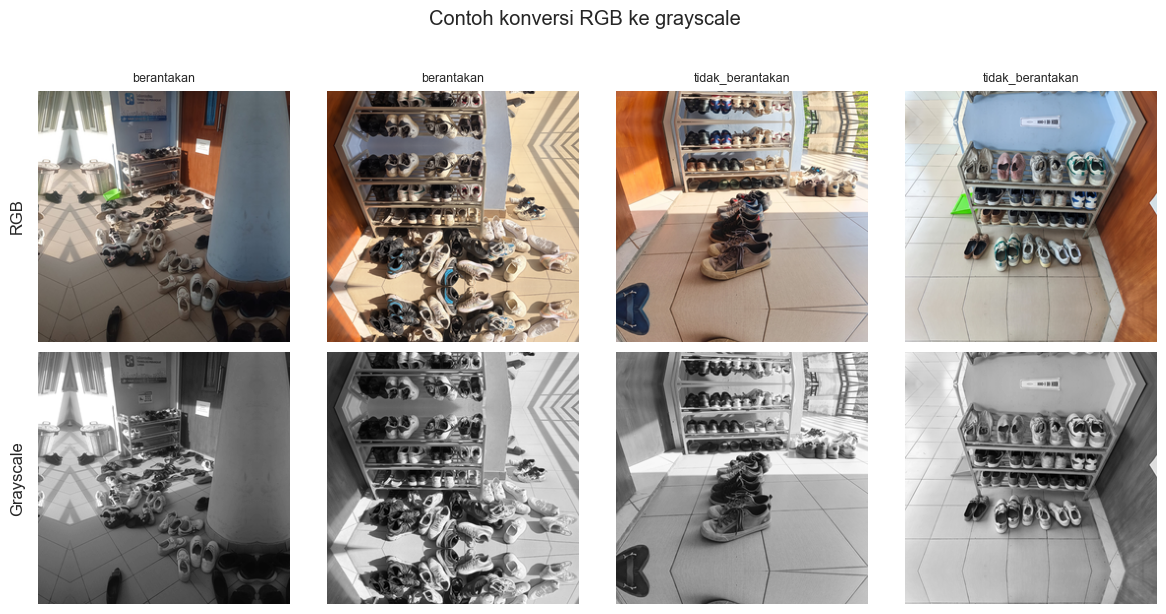

In [30]:
gray_cache = {
    str(record["path"]): np.asarray(Image.fromarray(image_cache[str(record["path"])]).convert("L"), dtype=np.uint8)
    for record in valid_records
}

samples = df_images.groupby("label", sort=False).head(2).reset_index(drop=True)
fig, axes = plt.subplots(2, len(samples), figsize=(3 * len(samples), 6))
if len(samples) == 1:
    axes = np.asarray(axes).reshape(2, 1)
for index, record in samples.iterrows():
    key = str(record["path"])
    axes[0, index].imshow(image_cache[key])
    axes[0, index].set_title(record["label"], fontsize=9)
    axes[1, index].imshow(gray_cache[key], cmap="gray", vmin=0, vmax=255)
    for ax in (axes[0, index], axes[1, index]):
        ax.axis("off")
axes[0, 0].text(-0.05, 0.5, "RGB", transform=axes[0, 0].transAxes,
                rotation=90, va="center", ha="right")
axes[1, 0].text(-0.05, 0.5, "Grayscale", transform=axes[1, 0].transAxes,
                rotation=90, va="center", ha="right")
fig.suptitle("Contoh konversi RGB ke grayscale", y=1.02)
plt.tight_layout()
plt.show()

## 6. Ekstraksi fitur tekstur GLCM

Setiap citra grayscale menghasilkan GLCM untuk jarak dan sudut yang dikonfigurasi. Matriks hitungan diubah menjadi probabilitas $P(i,j)$, lalu kelima fitur dihitung manual dengan Eq. (5)-(9). Bobot indeks dan rumus dibuat sekali agar tidak diulang untuk setiap gambar.

| Fitur | Rumus jurnal |
|---|---|
| Entropy (Eq. 5) | $-\sum\sum P(i,j)\log_2 P(i,j)$ |
| Contrast (Eq. 6) | $\sum\sum (i-j)^2 P(i,j)$ |
| Correlation (Eq. 7) | $\sum\sum \frac{(i-\mu_i)(j-\mu_j)P(i,j)}{\sigma_i\sigma_j}$ |
| Energy (Eq. 8) | $\sum\sum P(i,j)^2$ |
| Homogeneity (Eq. 9) | $\sum\sum \frac{P(i,j)}{1+|i-j|}$ |

Jika simpangan baku marginal GLCM nol, correlation ditetapkan 1.0. Nilai ini mengikuti konvensi untuk citra seragam dan mencegah NaN.

In [31]:
GLCM_INDEX = np.arange(GLCM_LEVELS, dtype=np.float64)
GLCM_ROW = GLCM_INDEX.reshape(1, GLCM_LEVELS, 1)
GLCM_COL = GLCM_INDEX.reshape(1, 1, GLCM_LEVELS)
GLCM_CONTRAST_WEIGHT = (GLCM_INDEX[:, None] - GLCM_INDEX[None, :]) ** 2
GLCM_HOMOGENEITY_WEIGHT = 1.0 / (1.0 + np.abs(GLCM_INDEX[:, None] - GLCM_INDEX[None, :]))


def build_glcm(gray, distances=GLCM_DISTANCES, angles=GLCM_ANGLES):
    """Buat GLCM; gunakan scikit-image bila ada, atau fallback NumPy yang setara."""
    image = gray.astype(np.uint8)
    if GLCM_LEVELS < 256:
        image = (image.astype(np.uint16) * GLCM_LEVELS // 256).astype(np.uint8)

    if SKIMAGE_AVAILABLE:
        return graycomatrix(image, distances=distances, angles=angles,
                            levels=GLCM_LEVELS, symmetric=True, normed=False)

    # Fallback sederhana agar notebook tetap berjalan bila scikit-image belum terpasang.
    height, width = image.shape
    result = np.zeros((GLCM_LEVELS, GLCM_LEVELS, len(distances), len(angles)), dtype=np.uint32)
    for distance_index, distance in enumerate(distances):
        for angle_index, angle in enumerate(angles):
            row_offset = int(round(-np.sin(angle) * distance))
            col_offset = int(round(np.cos(angle) * distance))
            row_start, row_stop = max(0, -row_offset), min(height, height - row_offset)
            col_start, col_stop = max(0, -col_offset), min(width, width - col_offset)
            first = image[row_start:row_stop, col_start:col_stop]
            second = image[row_start + row_offset:row_stop + row_offset,
                            col_start + col_offset:col_stop + col_offset]
            matrix = result[:, :, distance_index, angle_index]
            np.add.at(matrix, (first.ravel(), second.ravel()), 1)
            matrix += matrix.T
    return result


def glcm_features(gray, distances=GLCM_DISTANCES, angles=GLCM_ANGLES):
    """Hitung Eq. (5)-(9) manual; hasil dirata-ratakan atas jarak dan sudut."""
    matrices = build_glcm(gray, distances=distances, angles=angles)
    matrices = np.moveaxis(matrices, (2, 3), (0, 1)).reshape(-1, GLCM_LEVELS, GLCM_LEVELS)
    totals = matrices.sum(axis=(1, 2), keepdims=True).astype(np.float64)
    probabilities = np.divide(matrices, totals, out=np.zeros_like(matrices, dtype=np.float64), where=totals > 0)

    positive = probabilities > 0
    safe_probabilities = np.where(positive, probabilities, 1.0)
    energy = np.sum(probabilities ** 2, axis=(1, 2))                       # Eq. (8)
    entropy = -np.sum(probabilities * np.log2(safe_probabilities), axis=(1, 2))  # Eq. (5)
    contrast = np.sum(probabilities * GLCM_CONTRAST_WEIGHT, axis=(1, 2))    # Eq. (6)
    homogeneity = np.sum(probabilities * GLCM_HOMOGENEITY_WEIGHT, axis=(1, 2))  # Eq. (9)

    marginal_i = probabilities.sum(axis=2)
    marginal_j = probabilities.sum(axis=1)
    mean_i = marginal_i @ GLCM_INDEX
    mean_j = marginal_j @ GLCM_INDEX
    delta_i = GLCM_ROW - mean_i[:, None, None]
    delta_j = GLCM_COL - mean_j[:, None, None]
    std_i = np.sqrt(np.sum(probabilities * delta_i ** 2, axis=(1, 2)))
    std_j = np.sqrt(np.sum(probabilities * delta_j ** 2, axis=(1, 2)))
    covariance = np.sum(probabilities * delta_i * delta_j, axis=(1, 2))
    denominator = std_i * std_j
    correlation = np.divide(covariance, denominator, out=np.ones_like(covariance), where=denominator > 0)  # Eq. (7)

    return {
        "energy": float(energy.mean()),
        "entropy": float(entropy.mean()),
        "contrast": float(contrast.mean()),
        "correlation": float(correlation.mean()),
        "homogeneity": float(homogeneity.mean()),
    }

### Sanity check: fitur manual dan `graycoprops`

Pada satu citra, satu jarak, dan satu sudut, contrast, correlation, serta energy/ASM harus sejalan. Homogeneity memang berbeda karena Eq. (9) memakai $1+|i-j|$, sedangkan `graycoprops` memakai penyebut $1+(i-j)^2$. Bila scikit-image tidak terpasang, GLCM tetap dihitung dengan fallback NumPy dan perbandingan pustaka dilewati.

In [32]:
first_key = str(valid_records[0]["path"])
gray_sample = gray_cache[first_key]
manual = glcm_features(gray_sample, distances=[1], angles=[0])

if SKIMAGE_AVAILABLE:
    sample_glcm = graycomatrix(np.array(gray_sample, dtype=np.uint8, copy=True, order="C"), distances=[1], angles=[0], levels=GLCM_LEVELS,
                               symmetric=True, normed=True)
    comparison = pd.DataFrame({
        "manual (jurnal)": [manual["contrast"], manual["energy"], manual["correlation"], manual["homogeneity"]],
        "graycoprops": [
            graycoprops(sample_glcm, "contrast")[0, 0],
            graycoprops(sample_glcm, "ASM")[0, 0],
            graycoprops(sample_glcm, "correlation")[0, 0],
            graycoprops(sample_glcm, "homogeneity")[0, 0],
        ],
    }, index=["contrast", "energy (= ASM)", "correlation", "homogeneity (beda rumus)"])
    display(comparison)
    print("Homogeneity berbeda sesuai definisi rumus jurnal dan scikit-image.")
else:
    print("Perbandingan graycoprops dilewati: scikit-image tidak tersedia pada kernel ini.")
    print("Pasang scikit-image untuk menampilkan pembanding pustaka; rumus fitur notebook tetap dihitung manual.")
    display(pd.Series(manual, name="hasil manual (jurnal)").to_frame())

,manual (jurnal),graycoprops
contrast,218.505407,218.505407
energy (= ASM),0.001445,0.001445
correlation,0.963696,0.963696
homogeneity (beda rumus),0.424963,0.372190


Homogeneity berbeda sesuai definisi rumus jurnal dan scikit-image.


In [33]:
texture_rows = []
for record in tqdm(valid_records, desc="Ekstraksi fitur GLCM", mininterval=1.0):
    key = str(record["path"])
    texture_rows.append(glcm_features(gray_cache[key]))

df_tex = pd.DataFrame(texture_rows)
display(df_tex.head())

Ekstraksi fitur GLCM: 100%|██████████| 194/194 [00:05<00:00, 37.84it/s]


,energy,entropy,contrast,correlation,homogeneity
0,0.001411,11.829976,295.097826,0.950999,0.405904
1,0.000226,13.527227,911.011474,0.905965,0.253211
2,0.000353,12.993468,593.212927,0.910569,0.294538
3,0.000578,12.553205,468.954358,0.909524,0.304952
4,0.000922,11.617211,224.176686,0.956687,0.392705


## 7. Gabungkan fitur dan simpan CSV

Fitur warna dan tekstur digabung sesuai urutan kolom PRD. Kolom `filename` menjadi identitas gambar saja dan tidak digunakan oleh model klasifikasi.

In [34]:
FEATURES = color_columns + ["energy", "entropy", "contrast", "correlation", "homogeneity"]
expected_color_columns = ["filename"] + color_columns + ["label"]
expected_full_columns = ["filename"] + FEATURES + ["label"]

if len(FEATURES) != 14:
    raise RuntimeError(f"Jumlah fitur harus 14, ditemukan {len(FEATURES)}.")

texture_columns = ["energy", "entropy", "contrast", "correlation", "homogeneity"]
df_final = pd.concat([
    df_warna.drop(columns="label").reset_index(drop=True),
    df_tex[texture_columns].reset_index(drop=True),
], axis=1)
df_final["label"] = df_warna["label"].values
df_final = df_final[expected_full_columns]

if df_warna.columns.tolist() != expected_color_columns:
    raise RuntimeError("Urutan kolom fitur_warna.csv tidak sesuai PRD.")
if df_final.columns.tolist() != expected_full_columns:
    raise RuntimeError("Urutan kolom fitur_lengkap.csv tidak sesuai PRD.")
if df_warna[color_columns].isna().any().any() or df_final[FEATURES].isna().any().any():
    raise ValueError("Nilai NaN ditemukan dalam fitur. Periksa citra atau fungsi ekstraksi.")

path_csv_final = OUTPUT_DIR / CSV_FINAL
df_warna.to_csv(path_csv_warna, index=False)
df_final.to_csv(path_csv_final, index=False)
print(f"{path_csv_warna} | {len(color_columns)} fitur warna + filename + label | {df_warna.shape}")
print(f"{path_csv_final} | {len(FEATURES)} fitur total + filename + label | {df_final.shape}")
display(df_final.head())

C:\laragon\www\messy-shoe-cv\fitur_warna.csv | 9 fitur warna + filename + label | (194, 11)
C:\laragon\www\messy-shoe-cv\fitur_lengkap.csv | 14 fitur total + filename + label | (194, 16)


,filename,mean_R,mean_G,mean_B,std_R,std_G,std_B,skew_R,skew_G,skew_B,energy,entropy,contrast,correlation,homogeneity,label
0,berantakan/24-003 Berantakan 2.jpg,110.720367,105.561218,101.683975,56.894741,55.378934,54.183069,0.748670,0.701999,0.644443,0.001411,11.829976,295.097826,0.950999,0.405904,berantakan
1,berantakan/24-003 Berantakan 3.jpg,149.705353,130.862045,113.433289,73.453635,70.071445,63.511628,-0.222975,-0.139022,-0.126647,0.000226,13.527227,911.011474,0.905965,0.253211,berantakan
2,berantakan/24-003 berantakan.jpg,150.763809,115.106903,90.900269,69.306975,57.372256,54.139031,-0.136816,0.171352,0.531602,0.000353,12.993468,593.212927,0.910569,0.294538,berantakan
3,berantakan/24-006 Berantakan 1.jpg,120.780609,112.721039,109.308685,52.646323,50.919134,50.715847,-0.503351,-0.256659,-0.177175,0.000578,12.553205,468.954358,0.909524,0.304952,berantakan
4,berantakan/24-006 Berantakan 2.jpg,127.230789,120.406448,117.175781,53.968538,50.034993,48.653675,-0.789952,-0.584725,-0.433947,0.000922,11.617211,224.176686,0.956687,0.392705,berantakan


## 8. EDA fitur

Pemeriksaan data dilakukan bertahap dan setiap langkah diletakkan pada sel terpisah agar keluarannya mudah dibaca dan dibahas satu per satu: missing value, keseimbangan kelas, rata-rata per kelas, statistik deskriptif, sebaran tiap fitur, lalu korelasi antarfitur.


### 8.1 Pemeriksaan missing value

Memastikan ke-14 fitur numerik tidak memuat NaN sebelum masuk ke model.


In [35]:
missing_values = df_final[FEATURES].isna().sum().rename("missing")
print("Missing value pada fitur:")
display(missing_values.to_frame())

if missing_values.sum() > 0:
    raise ValueError("Ada nilai NaN pada fitur; klasifikasi dihentikan.")


Missing value pada fitur:


,missing
mean_R,0
mean_G,0
mean_B,0
std_R,0
std_G,0
std_B,0
skew_R,0
skew_G,0
skew_B,0
energy,0


### 8.2 Distribusi kelas

Menghitung jumlah dan proporsi citra per kelas untuk memastikan data seimbang.


In [36]:
class_counts = df_final["label"].value_counts().reindex(CLASS_LABELS, fill_value=0)

print("Jumlah data per kelas:")
display(class_counts.rename("jumlah").to_frame())

print("Proporsi kelas:")
display((class_counts / class_counts.sum()).rename("proporsi").to_frame().round(3))


Jumlah data per kelas:


,jumlah
label,
berantakan,97
tidak_berantakan,97


Proporsi kelas:


,proporsi
label,
berantakan,0.5
tidak_berantakan,0.5


### 8.3 Rata-rata fitur per kelas

Membandingkan nilai rata-rata setiap fitur pada kedua kelas sebagai gambaran awal fitur mana yang berpotensi memisahkan kelas.


In [37]:
print("Rata-rata fitur per kelas:")
display(df_final.groupby("label")[FEATURES].mean().reindex(CLASS_LABELS).T.round(3))


Rata-rata fitur per kelas:


label,berantakan,tidak_berantakan
mean_R,137.727,138.268
mean_G,127.558,128.620
mean_B,118.773,121.955
std_R,58.675,56.079
std_G,59.545,59.435
std_B,59.741,61.788
skew_R,-0.320,-0.285
skew_G,-0.137,-0.106
skew_B,-0.052,-0.093
energy,0.002,0.001


### 8.4 Statistik deskriptif

Menampilkan sebaran (count, mean, std, min, kuartil, max) seluruh fitur untuk memeriksa skala dan kemungkinan pencilan.


In [38]:
print("Statistik seluruh fitur:")
display(df_final[FEATURES].describe().T.round(3))


Statistik seluruh fitur:


,count,mean,std,min,25%,50%,75%,max
mean_R,194.0,137.997,19.075,76.256,126.065,139.785,150.569,178.817
mean_G,194.0,128.089,17.705,67.860,117.055,130.152,138.543,170.037
mean_B,194.0,120.364,18.382,67.368,107.467,120.390,131.269,162.528
std_R,194.0,57.377,10.480,33.326,50.820,57.692,64.925,89.635
std_G,194.0,59.490,7.566,33.643,53.659,59.699,64.339,85.370
std_B,194.0,60.764,7.597,31.298,55.498,60.798,65.586,80.410
skew_R,194.0,-0.303,0.468,-1.587,-0.625,-0.300,0.002,0.946
skew_G,194.0,-0.121,0.400,-1.359,-0.415,-0.139,0.150,0.895
skew_B,194.0,-0.073,0.398,-1.172,-0.364,-0.118,0.213,0.857
energy,194.0,0.001,0.003,0.000,0.000,0.001,0.001,0.035


### 8.5 Sebaran 14 fitur per kelas

Boxplot setiap fitur dipisah menurut kelas untuk melihat perbedaan median, sebaran, dan tumpang tindih antar kelas.


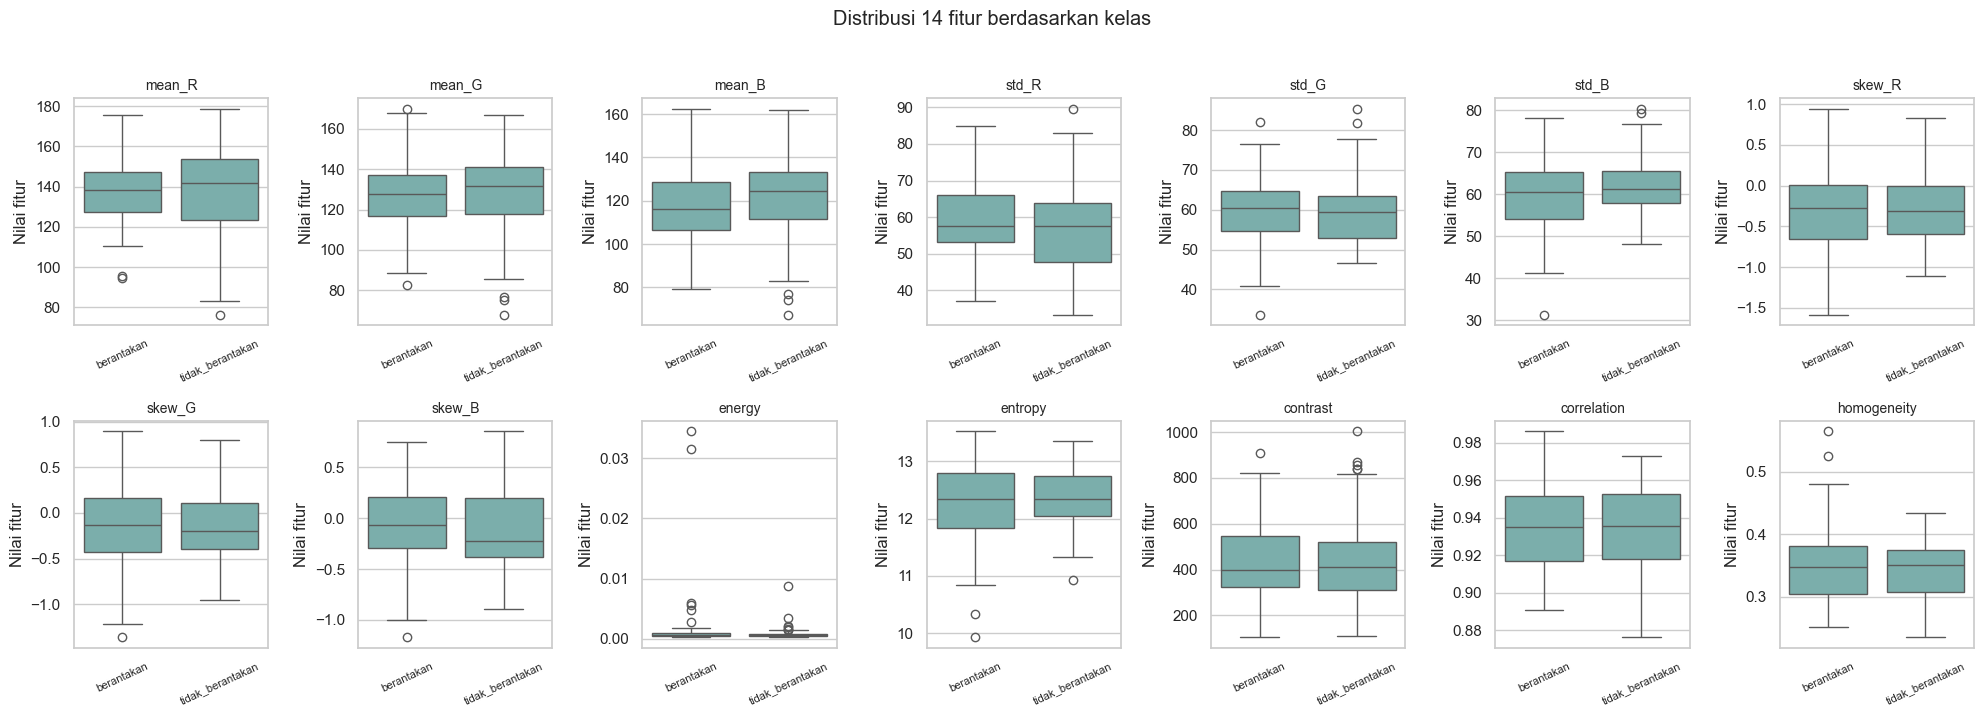

In [39]:
fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=df_final, x="label", y=feature, order=CLASS_LABELS, ax=ax, color="#72b7b2")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Nilai fitur")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Distribusi 14 fitur berdasarkan kelas", y=1.02)
plt.tight_layout()
plt.show()


### 8.6 Korelasi antarfitur

Heatmap korelasi Pearson antarfitur membantu mendeteksi fitur yang saling redundan, misalnya antar channel warna.


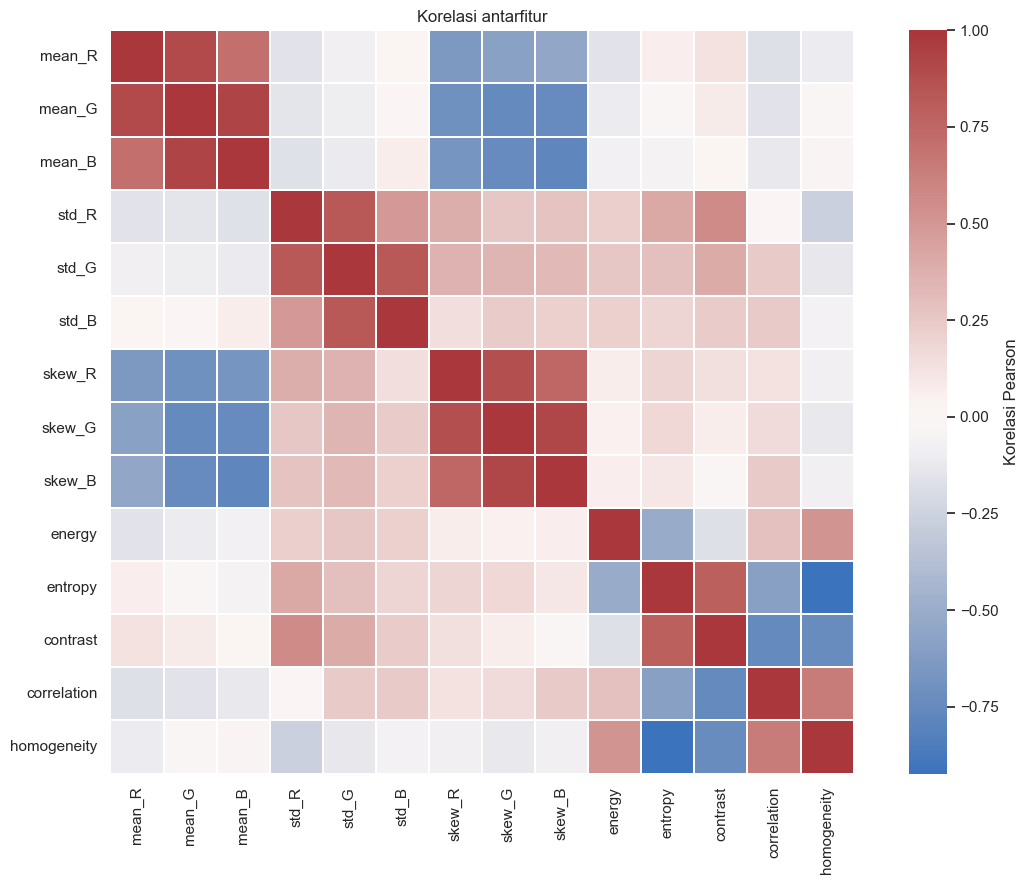

In [40]:
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(df_final[FEATURES].corr(), cmap="vlag", center=0, annot=False, square=True,
            linewidths=0.3, cbar_kws={"label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Korelasi antarfitur")
plt.tight_layout()
plt.show()


## 9. Perbandingan lima model baseline

Holdout dibuat lebih dahulu dengan `StratifiedGroupKFold`. Foto berawalan ID sama (misalnya `24-003`) hanya berada pada satu sisi split. Lima baseline dibandingkan memakai Stratified Group 5-fold CV yang sama pada data train; data test tidak dipakai untuk memilih model.

In [41]:
X_all = df_final[FEATURES].to_numpy(dtype=np.float64)  # filename dan group_id bukan fitur
label_to_number = {label: index for index, label in enumerate(CLASS_LABELS)}
y_all = df_final["label"].map(label_to_number).to_numpy(dtype=int)
groups_all = df_images["group_id"].astype(str).to_numpy()
if len(np.unique(y_all)) != 2:
    raise ValueError("Klasifikasi memerlukan tepat dua kelas yang terwakili.")

# Fold pertama menjadi holdout sekitar 20%; tidak ada ID yang bocor antarsplit.
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer_cv.split(X_all, y_all, groups_all))
X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
groups_train, groups_test = groups_all[train_idx], groups_all[test_idx]
if set(groups_train) & set(groups_test):
    raise RuntimeError("Kebocoran grup ditemukan antara train dan test.")

print(f"Train: {len(train_idx)} gambar, {len(np.unique(groups_train))} grup")
print(f"Test: {len(test_idx)} gambar, {len(np.unique(groups_test))} grup")
test_labels = pd.Series(y_test).map({v: k for k, v in label_to_number.items()})
display(test_labels.value_counts().reindex(CLASS_LABELS, fill_value=0).rename("jumlah pada test").to_frame())

cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
baseline_models = {
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, gamma=0.01, random_state=RANDOM_STATE)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.5, random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1),
    "K-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights="distance")),
}

score_rows, cv_scores = [], {}
for model_name, model in baseline_models.items():
    scores = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring="accuracy")
    cv_scores[model_name] = scores
    score_rows.append({"model": model_name, "akurasi_mean": float(scores.mean()),
                       "akurasi_std": float(scores.std(ddof=0))})
    print(f"{model_name}: accuracy CV train = {scores.mean():.4f} +/- {scores.std(ddof=0):.4f}")

hasil = pd.DataFrame(score_rows).sort_values("akurasi_mean", ascending=False).reset_index(drop=True)
best_name = hasil.loc[0, "model"]
model_terbaik = baseline_models[best_name]
print(f"Model baseline terbaik dari CV train: {best_name}")
display(hasil.round(4))
print(f"Hanya {best_name} diteruskan ke evaluasi baseline holdout; empat model lain hanya untuk perbandingan CV.")

Train: 158 gambar, 45 grup
Test: 36 gambar, 13 grup


,jumlah pada test
berantakan,20
tidak_berantakan,16


SVM (RBF): accuracy CV train = 0.5827 +/- 0.0863
Logistic Regression: accuracy CV train = 0.5703 +/- 0.0563
Random Forest: accuracy CV train = 0.6828 +/- 0.0348
Extra Trees: accuracy CV train = 0.6847 +/- 0.0627
K-NN (k=5): accuracy CV train = 0.7138 +/- 0.0673
Model baseline terbaik dari CV train: K-NN (k=5)


,model,akurasi_mean,akurasi_std
0,K-NN (k=5),0.7138,0.0673
1,Extra Trees,0.6847,0.0627
2,Random Forest,0.6828,0.0348
3,SVM (RBF),0.5827,0.0863
4,Logistic Regression,0.5703,0.0563


Hanya K-NN (k=5) diteruskan ke evaluasi baseline holdout; empat model lain hanya untuk perbandingan CV.


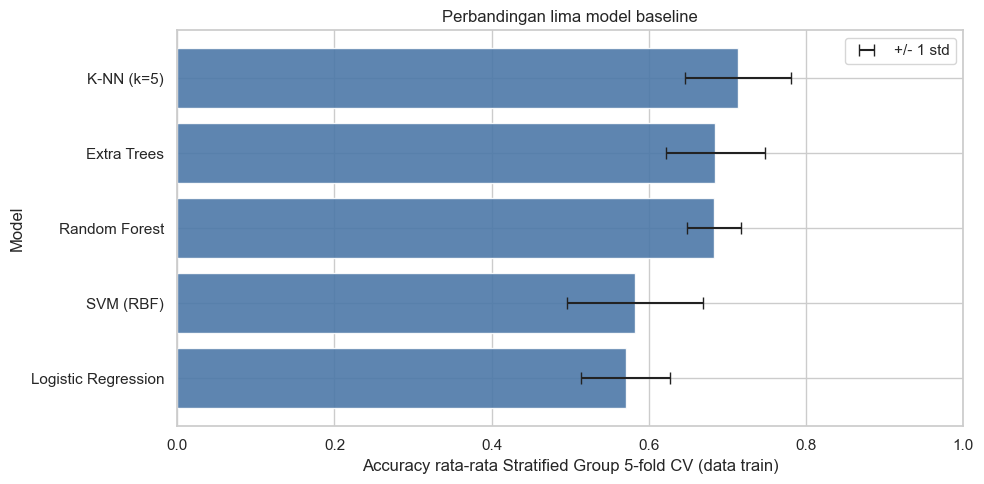

In [42]:
plot_data = hasil.sort_values("akurasi_mean", ascending=True).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(plot_data))
ax.barh(positions, plot_data["akurasi_mean"], color="#4c78a8", alpha=0.9)
ax.errorbar(plot_data["akurasi_mean"], positions, xerr=plot_data["akurasi_std"],
            fmt="none", ecolor="#222222", capsize=4, label="+/- 1 std")
ax.set_yticks(positions, plot_data["model"])
ax.set_xlim(0, 1)
ax.set_xlabel("Accuracy rata-rata Stratified Group 5-fold CV (data train)")
ax.set_ylabel("Model")
ax.set_title("Perbandingan lima model baseline")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Tuning model terbaik dan evaluasi holdout

Extra Trees dan K-NN dituning pada data train saja dengan group-aware CV. Setelah baseline terbaik dipilih, tuning hanya diterapkan bila sesuai dengan model pemenang. Holdout tetap tidak dipakai untuk memilih parameter.

Extra Trees CV terbaik setelah tuning: 0.6995
Parameter Extra Trees: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
K-NN CV terbaik setelah tuning: 0.7279
Parameter K-NN: {'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
Model baseline pemenang: K-NN hasil tuning.
Baseline K-NN (k=5) holdout: 0.8333
K-NN (k=5) hasil tuning holdout: 0.7500


,varian,accuracy holdout
0,K-NN (k=5) baseline,0.833333
1,K-NN (k=5) hasil tuning,0.750000



Model final berdasarkan CV: K-NN (k=5)
Jumlah train: 158 | jumlah test: 36
Accuracy holdout: 0.7500 (75.00%)

Classification report:
                  precision    recall  f1-score   support

      berantakan      0.762     0.800     0.780        20
tidak_berantakan      0.733     0.688     0.710        16

        accuracy                          0.750        36
       macro avg      0.748     0.744     0.745        36
    weighted avg      0.749     0.750     0.749        36



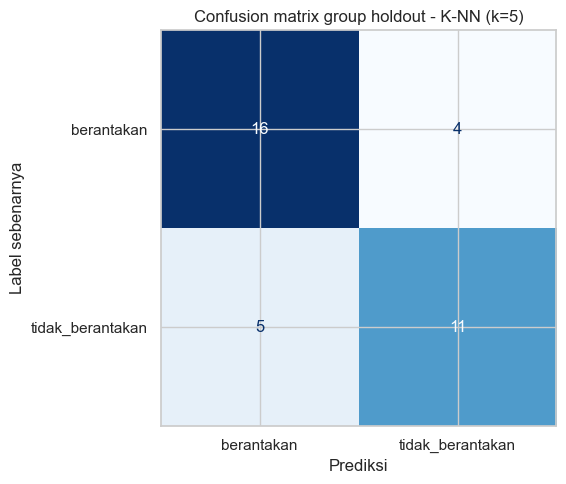

In [43]:
# Grid terbatas untuk tuning Extra Trees.
et_param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [None, 15],
    "min_samples_leaf": [1, 3],
    "max_features": ["sqrt"],
}
et_search = GridSearchCV(
    ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=et_param_grid, scoring="accuracy", cv=cv, n_jobs=1, refit=True,
)
et_search.fit(X_train, y_train, groups=groups_train)
print(f"Extra Trees CV terbaik setelah tuning: {et_search.best_score_:.4f}")
print("Parameter Extra Trees:", et_search.best_params_)

# K-NN memakai Pipeline agar StandardScaler selalu di-fit hanya pada fold train.
knn_pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier())
knn_param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2],
}
knn_search = GridSearchCV(
    knn_pipeline, param_grid=knn_param_grid, scoring="accuracy", cv=cv, n_jobs=1, refit=True,
)
knn_search.fit(X_train, y_train, groups=groups_train)
print(f"K-NN CV terbaik setelah tuning: {knn_search.best_score_:.4f}")
print("Parameter K-NN:", knn_search.best_params_)

if best_name == "Extra Trees":
    estimator_final = clone(et_search.best_estimator_)
    print("Model baseline pemenang: Extra Trees hasil tuning.")
elif best_name == "K-NN (k=5)":
    estimator_final = clone(knn_search.best_estimator_)
    print("Model baseline pemenang: K-NN hasil tuning.")
else:
    estimator_final = clone(model_terbaik)
    print(f"Model baseline pemenang: {best_name}; konfigurasi baseline dipakai.")

# Catat baseline pemenang sebelum tuning untuk perbandingan deskriptif pada holdout.
model_baseline_holdout = clone(model_terbaik)
model_baseline_holdout.fit(X_train, y_train)
y_pred_baseline = model_baseline_holdout.predict(X_test)
akurasi_baseline_holdout = accuracy_score(y_test, y_pred_baseline)

model_final = clone(estimator_final)
model_final.fit(X_train, y_train)
y_pred = model_final.predict(X_test)
akurasi_test = accuracy_score(y_test, y_pred)
print(f"Baseline {best_name} holdout: {akurasi_baseline_holdout:.4f}")
print(f"{best_name} hasil tuning holdout: {akurasi_test:.4f}")
display(pd.DataFrame({
    "varian": [f"{best_name} baseline", f"{best_name} hasil tuning"],
    "accuracy holdout": [akurasi_baseline_holdout, akurasi_test],
}))
print(f"\nModel final berdasarkan CV: {best_name}")
print(f"Jumlah train: {len(y_train)} | jumlah test: {len(y_test)}")
print(f"Accuracy holdout: {akurasi_test:.4f} ({akurasi_test * 100:.2f}%)")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=np.arange(len(CLASS_LABELS)),
                            target_names=CLASS_LABELS, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=np.arange(len(CLASS_LABELS)), display_labels=CLASS_LABELS,
    cmap="Blues", values_format="d", colorbar=False, ax=ax
)
ax.set_title(f"Confusion matrix group holdout - {best_name}")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label sebenarnya")
plt.tight_layout()
plt.show()

### 10.1 Ukuran ensemble pohon

Extra Trees adalah kumpulan pohon. Jumlah pohon model final mengikuti `n_estimators` hasil tuning, sedangkan jumlah pohon pada setiap kandidat/fold CV dapat berbeda. Sel berikut menampilkan jumlah yang benar-benar dipakai model final.

In [44]:
from sklearn.tree import plot_tree

if hasattr(model_final, "estimators_"):
    trees = model_final.estimators_
    n_estimators_final = model_final.get_params().get("n_estimators")
    depths = np.array([tree.tree_.max_depth for tree in trees])
    nodes = np.array([tree.tree_.node_count for tree in trees])
    leaves = np.array([tree.tree_.n_leaves for tree in trees])
    print(f"Model final: {best_name}")
    print(f"Parameter n_estimators: {n_estimators_final}")
    print(f"Jumlah pohon hasil fit: {len(trees)}")
    display(pd.DataFrame({
        "statistik": ["kedalaman minimum", "kedalaman rata-rata", "kedalaman maksimum",
                      "jumlah leaf rata-rata", "jumlah node rata-rata", "total node seluruh pohon"],
        "nilai": [f"{int(depths.min())}", f"{depths.mean():.2f}", f"{int(depths.max())}",
                  f"{leaves.mean():.1f}", f"{nodes.mean():.1f}", f"{int(nodes.sum())}"],
    }))
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(depths, bins=15, color="#4c78a8", ax=ax)
    ax.set_title(f"Sebaran kedalaman {len(trees)} pohon Extra Trees")
    ax.set_xlabel("Kedalaman maksimum tiap pohon")
    ax.set_ylabel("Jumlah pohon")
    plt.tight_layout()
    plt.show()
else:
    print(f"Model final ({best_name}) bukan ensemble pohon; tidak ada pohon untuk dihitung.")

Model final (K-NN (k=5)) bukan ensemble pohon; tidak ada pohon untuk dihitung.


Diagram berikut menampilkan satu pohon dari ensemble model final sampai kedalaman 2 agar strukturnya terbaca. Ini ilustrasi satu pohon, bukan keseluruhan ensemble.

In [45]:
if hasattr(model_final, "estimators_"):
    fig, ax = plt.subplots(figsize=(16, 8))
    plot_tree(
        model_final.estimators_[0],
        max_depth=2,
        feature_names=FEATURES,
        class_names=CLASS_LABELS,
        filled=True,
        rounded=True,
        impurity=False,
        fontsize=8,
        ax=ax,
    )
    ax.set_title(f"Contoh pohon ke-1 dari {len(model_final.estimators_)} (ditampilkan sampai kedalaman 2)")
    plt.tight_layout()
    plt.show()
else:
    print("Visualisasi pohon dilewati karena model terbaik bukan ensemble pohon.")


Visualisasi pohon dilewati karena model terbaik bukan ensemble pohon.


## 10.2 Eksperimen opsional: HOG dan LBP

Eksperimen ini membandingkan fitur PRD dengan tambahan HOG dan LBP memakai model baseline pemenang hasil tuning serta split grup yang sama. Hasilnya tidak mengubah CSV inti 14 fitur. Representasi dipilih berdasarkan CV train sebelum accuracy holdout diperiksa.

In [46]:
if not SKIMAGE_AVAILABLE:
    print("Eksperimen HOG/LBP dilewati karena scikit-image belum terpasang.")
    optional_feature_results = pd.DataFrame()
    optional_best_name = None
    optional_test_accuracy = np.nan
else:
    hog_rows, lbp_rows = [], []
    lbp_bins = np.arange(-0.5, 10.5, 1.0)  # P=8 uniform LBP menghasilkan kode 0..9
    for record in tqdm(valid_records, desc="Ekstraksi fitur opsional HOG/LBP", mininterval=1.0):
        gray = gray_cache[str(record["path"])]
        hog_rows.append(hog(
            gray.astype(np.float32) / 255.0,
            orientations=9,
            pixels_per_cell=(32, 32),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True,
        ))
        lbp_image = local_binary_pattern(gray, P=8, R=1, method="uniform")
        histogram, _ = np.histogram(lbp_image, bins=lbp_bins)
        histogram = histogram.astype(np.float64)
        histogram /= histogram.sum()
        lbp_rows.append(histogram)

    X_hog = np.column_stack([X_all, np.asarray(hog_rows)])
    X_lbp = np.column_stack([X_all, np.asarray(lbp_rows)])
    feature_variants = {
        "RGB + GLCM (14 fitur)": X_all,
        "RGB + GLCM + HOG (opsional)": X_hog,
        "RGB + GLCM + LBP (opsional)": X_lbp,
    }
    optional_rows = []
    for variant_name, X_variant in feature_variants.items():
        scores = cross_val_score(
            clone(estimator_final),
            X_variant[train_idx], y_train,
            groups=groups_train, cv=cv, scoring="accuracy",
        )
        optional_rows.append({
            "representasi fitur": variant_name,
            "akurasi CV mean": float(scores.mean()),
            "akurasi CV std": float(scores.std(ddof=0)),
            "jumlah fitur": X_variant.shape[1],
        })
    optional_feature_results = pd.DataFrame(optional_rows).sort_values(
        "akurasi CV mean", ascending=False
    ).reset_index(drop=True)
    optional_best_name = optional_feature_results.loc[0, "representasi fitur"]
    print("Representasi dipilih berdasarkan mean CV train:", optional_best_name)
    display(optional_feature_results.round(4))

    optional_model = clone(estimator_final)
    X_optional = feature_variants[optional_best_name]
    optional_model.fit(X_optional[train_idx], y_train)
    optional_prediction = optional_model.predict(X_optional[test_idx])
    optional_test_accuracy = accuracy_score(y_test, optional_prediction)
    print(f"Accuracy holdout eksperimen opsional: {optional_test_accuracy:.4f}")

Ekstraksi fitur opsional HOG/LBP: 100%|██████████| 194/194 [00:03<00:00, 51.91it/s]


Representasi dipilih berdasarkan mean CV train: RGB + GLCM (14 fitur)


,representasi fitur,akurasi CV mean,akurasi CV std,jumlah fitur
0,RGB + GLCM (14 fitur),0.7279,0.0645,14
1,RGB + GLCM + HOG (opsional),0.6623,0.0748,1778
2,RGB + GLCM + LBP (opsional),0.6088,0.0578,24


Accuracy holdout eksperimen opsional: 0.7500


## 11. Kesimpulan & Analisis

Isi bagian ini oleh kelompok setelah melihat hasil. Bedakan hasil baseline PRD dari eksperimen fitur opsional.

- Model baseline mana yang unggul pada group-aware CV dan bagaimana hasil holdout-nya?
- Apakah tuning Extra Trees membantu pada CV dan holdout?
- Apakah HOG atau LBP membantu pada CV train dan holdout? Pemilihan varian harus berdasarkan CV train.
- Kelas mana yang lebih sering salah diklasifikasikan pada confusion matrix?
- Bagaimana jumlah grup ID, variasi gambar, dan jumlah data membatasi kesimpulan?

## Ringkasan hasil eksekusi

Tabel ini dirangkai langsung dari hasil CV dan evaluasi holdout pada eksekusi notebook; angka tidak ditulis manual.

In [47]:
summary_table = hasil.copy()
summary_table["accuracy CV train (mean +/- std)"] = summary_table.apply(
    lambda row: f"{row['akurasi_mean']:.4f} +/- {row['akurasi_std']:.4f}", axis=1
)
summary_table = summary_table[["model", "accuracy CV train (mean +/- std)"]]
print("Perbandingan lima baseline:")
display(summary_table)
print(f"Baseline terbaik: {best_name}")
print(f"Extra Trees CV setelah tuning: {et_search.best_score_:.4f}")
print(f"K-NN CV setelah tuning: {knn_search.best_score_:.4f}")
print(f"Accuracy holdout baseline sebelum tuning: {akurasi_baseline_holdout:.4f}")
print(f"Accuracy holdout model hasil tuning: {akurasi_test:.4f}")
if optional_best_name is not None:
    print(f"Fitur opsional terbaik dari CV: {optional_best_name}")
    print(f"Accuracy holdout fitur opsional: {optional_test_accuracy:.4f}")
print(f"CSV fitur warna: {path_csv_warna}")
print(f"CSV fitur lengkap: {path_csv_final}")

Perbandingan lima baseline:


,model,accuracy CV train (mean +/- std)
0,K-NN (k=5),0.7138 +/- 0.0673
1,Extra Trees,0.6847 +/- 0.0627
2,Random Forest,0.6828 +/- 0.0348
3,SVM (RBF),0.5827 +/- 0.0863
4,Logistic Regression,0.5703 +/- 0.0563


Baseline terbaik: K-NN (k=5)
Extra Trees CV setelah tuning: 0.6995
K-NN CV setelah tuning: 0.7279
Accuracy holdout baseline sebelum tuning: 0.8333
Accuracy holdout model hasil tuning: 0.7500
Fitur opsional terbaik dari CV: RGB + GLCM (14 fitur)
Accuracy holdout fitur opsional: 0.7500
CSV fitur warna: C:\laragon\www\messy-shoe-cv\fitur_warna.csv
CSV fitur lengkap: C:\laragon\www\messy-shoe-cv\fitur_lengkap.csv
